In [13]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [14]:
df=pd.read_csv('results.csv')

In [15]:
df.head()

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0.0,0.0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4.0,2.0,Friendly,London,England,False
2,1874-03-07,Scotland,England,2.0,1.0,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2.0,2.0,Friendly,London,England,False
4,1876-03-04,Scotland,England,3.0,0.0,Friendly,Glasgow,Scotland,False


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49477 entries, 0 to 49476
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        49477 non-null  object 
 1   home_team   49477 non-null  object 
 2   away_team   49477 non-null  object 
 3   home_score  49433 non-null  float64
 4   away_score  49433 non-null  float64
 5   tournament  49477 non-null  object 
 6   city        49477 non-null  object 
 7   country     49477 non-null  object 
 8   neutral     49477 non-null  bool   
dtypes: bool(1), float64(2), object(6)
memory usage: 3.1+ MB


In [17]:
df['date']=pd.to_datetime(df['date'])

In [18]:
df=df.sort_values('date').reset_index(drop=True)

In [19]:
df.tail()

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
49472,2026-06-27,Colombia,Portugal,NaN,NaN,FIFA World Cup,Miami Gardens,United States,True
49473,2026-06-27,Panama,England,NaN,NaN,FIFA World Cup,East Rutherford,United States,True
49474,2026-06-27,Algeria,Austria,NaN,NaN,FIFA World Cup,Kansas City,United States,True
49475,2026-06-27,Jordan,Argentina,NaN,NaN,FIFA World Cup,Arlington,United States,True
49476,2026-06-27,Croatia,Ghana,NaN,NaN,FIFA World Cup,Philadelphia,United States,True


In [20]:
teams=pd.concat([df['home_team'],df['away_team']]).unique()

In [21]:
elo={team:1500 for team in teams}
k=30
home_ad=100
home_elos=[]
away_elos=[]
elo_diffs=[]
targets=[]

In [22]:
for _, row in df.iterrows():
  home=row['home_team']
  away=row['away_team']
  home_rating=elo[home]
  away_rating=elo[away]

  if row['neutral']:
    eff_home_rating=home_rating
  else:
    eff_home_rating=home_rating+home_ad

  home_elos.append(home_rating)
  away_elos.append(away_rating)
  elo_diffs.append(eff_home_rating-away_rating)

  if row['home_score']>row['away_score']:
    actual_home=1.0
  elif row['home_score']<row['away_score']:
    actual_home=0.0
  else:
    actual_home=0.5

  # Map the actual_home values to integer targets: 0 for away win, 1 for draw, 2 for home win
  if actual_home == 0.0:
      targets.append(0)
  elif actual_home == 0.5:
      targets.append(1)
  else:
      targets.append(2)

  exp_home=1/(1+10**((away_rating-eff_home_rating)/400))
  elo[home]=home_rating+k*(actual_home-exp_home)
  elo[away]=away_rating+k* ((1-actual_home)-(1-exp_home))

In [23]:
df['home_elo'] = home_elos
df['away_elo'] = away_elos
df['elo_diff'] = elo_diffs
df['target'] = targets

In [24]:
X = df[['elo_diff', 'neutral']]
y = df['target']

In [25]:
train_df = df[
    (df['date'].dt.year >= 2010) &
    (df['date'].dt.year <= 2022)
]
test_df = df[
    (df['date'].dt.year >= 2023) &
    (df['date'].dt.year <= 2025)
]

X_train = train_df[['elo_diff', 'neutral']]
y_train = train_df['target']

X_test = test_df[['elo_diff', 'neutral']]
y_test = test_df['target']

In [26]:
print("Training matches:", len(train_df))
print("Testing matches:", len(test_df))

print("Train years:",
      train_df['date'].dt.year.min(),
      "-",
      train_df['date'].dt.year.max())

print("Test years:",
      test_df['date'].dt.year.min(),
      "-",
      test_df['date'].dt.year.max())

Training matches: 12219
Testing matches: 3287
Train years: 2010 - 2022
Test years: 2023 - 2025


In [27]:
from sklearn.linear_model import LogisticRegression

# Use 'multinomial' for multi-class classification and 'lbfgs' solver
model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)

model.fit(X_train, y_train)

pred = model.predict(X_test)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [28]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred))

Accuracy: 0.6045025859446304
              precision    recall  f1-score   support

           0       0.57      0.64      0.60       991
           1       0.00      0.00      0.00       750
           2       0.62      0.88      0.73      1546

    accuracy                           0.60      3287
   macro avg       0.40      0.50      0.44      3287
weighted avg       0.46      0.60      0.52      3287



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**FIFA PREDICTOR**
Enter Home Team: Spain
Enter Away Team: Argentina
Neutral venue? (y/n): y


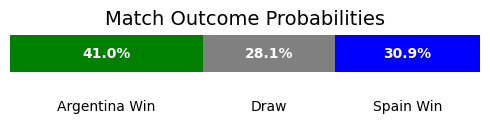


--------------------------
Prediction : Argentina WIN
--------------------------



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

HOME_ADVANTAGE = 100

while True:

    print("**FIFA PREDICTOR**")
    home_team = input("Enter Home Team: ").strip()
    away_team = input("Enter Away Team: ").strip()

    neutral_input = input("Neutral venue? (y/n): ").strip().lower()
    neutral = (neutral_input == 'y')

    # Check whether teams exist
    if home_team not in elo:
        print(f"{home_team} not found!")
        continue

    if away_team not in elo:
        print(f"{away_team} not found!")
        continue

    # Get current Elo ratings
    home_elo = elo[home_team]
    away_elo = elo[away_team]

    # Apply home advantage
    if neutral:
        effective_home_elo = home_elo
    else:
        effective_home_elo = home_elo + HOME_ADVANTAGE

    elo_diff = effective_home_elo - away_elo

    X_new = pd.DataFrame({
        'elo_diff': [elo_diff],
        'neutral': [neutral]
    })

    # Get probabilities for all three outcomes
    probabilities = model.predict_proba(X_new)[0]
    prob_away_win = probabilities[0]
    prob_draw = probabilities[1]
    prob_home_win = probabilities[2]

    prediction = model.predict(X_new)[0]

    # Plotting the horizontal stacked bar chart
    fig, ax = plt.subplots(figsize=(5, 2))

    outcomes = [f'{away_team} Win', 'Draw', f'{home_team} Win']
    probs = [prob_away_win, prob_draw, prob_home_win]
    colors = ['green', 'grey', 'blue'] # Purple, light blue, dark purple

    # Starting position for stacking
    left = 0
    for i in range(len(outcomes)):
        ax.barh(0, probs[i], left=left, height=0.5, color=colors[i])

        # Add percentage labels in the center of each segment
        if probs[i] > 0.03: # Only add label if segment is wide enough
            ax.text(left + probs[i] / 2, 0, f'{probs[i]:.1%}', va='center', ha='center', color='white', fontweight='bold')
        left += probs[i]

    ax.set_xlim(0, 1) # Probabilities sum to 1
    ax.set_yticks([]) # Hide y-axis ticks
    ax.set_title('Match Outcome Probabilities', fontsize=14)
    ax.set_xlabel('Probability', fontsize=10)

    # Add outcome names below the bar
    left = 0
    for i in range(len(outcomes)):
        if probs[i] > 0.01: # Only add outcome name if segment is wide enough
            ax.text(left + probs[i] / 2, -0.6, outcomes[i], va='top', ha='center', fontsize=10)
        left += probs[i]

    ax.axis('off') # Hide the axis completely for a cleaner look
    plt.tight_layout()
    plt.show()
    print("\n--------------------------")


    if prediction == 2:
        print(f"Prediction : {home_team} WIN")
    elif prediction == 1:
        print(f"Prediction : DRAW")
    else:
        print(f"Prediction : {away_team} WIN")
    print("--------------------------\n")

    cont = input("Predict another match? (y/n): ").lower()
    if cont != 'y':
        break